# Aula 12 - MLP para classificação e regressão no CRISP-DM

Vamos acompanhar um projeto de **manutenção preditiva** do início ao fim. Usaremos dados de sensores para responder a duas perguntas relacionadas: classificar se houve falha na máquina e estimar a vibração medida. As tarefas compartilham o contexto e as entradas, mas diferem no alvo, na saída e na avaliação.

A aula preserva o foco em arquitetura, treinamento, regularização, validação e comparação da MLP com Random Forest. O dataset de Materiais é sintético e serve para aprendizagem, não para validar um sistema industrial real. Execute as células na ordem.

## Objetivos

- Compreender como uma MLP aprende padrões por camadas e ajustes sucessivos.
- Distinguir classificação de regressão e escolher métricas adequadas.
- Preparar os dados sem vazamento de informação.
- Interpretar regularização, parada antecipada e generalização.
- Comparar MLP e Random Forest com o mesmo protocolo experimental.
- Relacionar os resultados às decisões do CRISP-DM.

# CRISP-DM 1 - Entendimento do negócio

Uma planta industrial quer reduzir paradas não planejadas. Sensores registram temperatura, vibração, corrente, pressão e horas de operação. A equipe deseja antecipar inspeções.

O projeto produz dois apoios: (1) uma probabilidade de falha para priorizar inspeções; (2) uma estimativa numérica da vibração medida para planejar manutenção. Um falso negativo pode deixar uma falha passar; um falso positivo pode provocar uma inspeção desnecessária. Na regressão, importam o tamanho e o padrão do erro na unidade do sensor. A equipe deve definir custos e capacidade operacional. O modelo apoia profissionais, não substitui decisões de segurança.

# CRISP-DM 2 - Entendimento dos dados

Carregamos o dataset local e verificamos dimensões, colunas, tipos, ausências e distribuição dos alvos. O balanceamento da classe afeta a interpretação: se falhas forem raras, acurácia alta pode coexistir com falhas não detectadas. O resumo da vibração revela escala e dispersão para interpretar os erros.

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

caminho = Path("../Materiais/CRISP_DM_Random_Forest_Manutencao_Preditiva.csv")
if not caminho.exists():
    caminho = Path("Materiais/CRISP_DM_Random_Forest_Manutencao_Preditiva.csv")
dados = pd.read_csv(caminho)
print("Dimensões:", dados.shape)
print("Colunas:", dados.columns.tolist())
display(dados.head())
display(dados.dtypes.rename("tipo").to_frame())
display(dados.isna().sum().rename("ausentes").to_frame())

Dimensões: (9000, 14)
Colunas: ['equipamento_id', 'tempo_operacao_horas', 'tipo_combustivel', 'turno_trabalho', 'regiao_instalacao', 'temperatura_celsius', 'vibracao_mm_s', 'pressao_psi', 'dias_desde_ultima_revisao', 'historico_falhas_anteriores', 'ruido_frequencia_hz', 'tag_rfid_inventario', 'firmware_serial_hash', 'falha_maquina']


,equipamento_id,tempo_operacao_horas,tipo_combustivel,turno_trabalho,regiao_instalacao,temperatura_celsius,vibracao_mm_s,pressao_psi,dias_desde_ultima_revisao,historico_falhas_anteriores,ruido_frequencia_hz,tag_rfid_inventario,firmware_serial_hash,falha_maquina
0,EQP-30000,12311.9,Diesel,Manha,Oeste,76.8,1.17,99.2,252,0,0.19,960139,FW-9082F,1
1,EQP-30001,5375.9,Diesel,Tarde,Leste,65.8,2.50,82.5,204,1,6.80,157884,FW-945FC,1
2,EQP-30002,NaN,Eletrico,Manha,Oeste,41.4,3.35,77.9,361,0,-3.10,890278,FW-29997,1
3,EQP-30003,7507.9,Eletrico,Tarde,Sul,104.2,3.95,116.0,206,0,5.22,619581,FW-C818A,1
4,EQP-30004,11892.7,Diesel,Tarde,Oeste,71.9,10.94,114.2,87,1,-33.68,204222,FW-E0FDC,1


,tipo
equipamento_id,str
tempo_operacao_horas,float64
tipo_combustivel,str
turno_trabalho,str
regiao_instalacao,str
temperatura_celsius,float64
vibracao_mm_s,float64
pressao_psi,float64
dias_desde_ultima_revisao,int64
historico_falhas_anteriores,int64


,ausentes
equipamento_id,0
tempo_operacao_horas,450
tipo_combustivel,0
turno_trabalho,0
regiao_instalacao,0
temperatura_celsius,0
vibracao_mm_s,450
pressao_psi,0
dias_desde_ultima_revisao,0
historico_falhas_anteriores,0


Inspecionamos os alvos antes de modelar. A proporção descreve frequência, não causa. O arquivo tem 450 medições ausentes no alvo de regressão; vamos tratá-las na preparação. O alvo de classificação é `falha_maquina`; `vibracao_mm_s` é o alvo contínuo de regressão.

In [2]:
alvo_classe = "falha_maquina"
alvo_regressao = "vibracao_mm_s"
display(dados[alvo_classe].value_counts().rename("quantidade").to_frame())
display(dados[alvo_classe].value_counts(normalize=True).rename("proporção").to_frame())
display(dados[alvo_regressao].describe().to_frame())

,quantidade
falha_maquina,
1,7186
0,1814


,proporção
falha_maquina,
1,0.798444
0,0.201556


,vibracao_mm_s
count,8550.000000
mean,16.753473
std,341.635472
min,0.500000
25%,1.842500
50%,3.700000
75%,6.790000
max,9999.000000


# CRISP-DM 3 - Preparação dos dados

Separaremos alvos e entradas, removendo identificadores. Em uma aplicação, confirme que toda entrada está disponível no instante da previsão; usar informação posterior ao evento causa vazamento. Dividimos treino e teste antes do escalonamento. O escalonador aprende apenas no treino, dentro do pipeline. A MLP precisa de entradas em escalas comparáveis; Random Forest não exige essa transformação. A mesma partição de casos permite comparar os modelos com justiça.

In [3]:
from sklearn.model_selection import train_test_split

alvo_classe = "falha_maquina"
alvo_regressao = "vibracao_mm_s"
ids = [c for c in ["id", "machine_id", "timestamp", "equipamento_id"] if c in dados.columns]
excluir = ids + [alvo_classe, alvo_regressao]
atributos = [c for c in dados.select_dtypes(include="number").columns if c not in excluir]
X = dados[atributos].copy()
yc = dados[alvo_classe].astype(int)
yr = dados[alvo_regressao].astype(float)
print("Entradas:", atributos)

# O rótulo de regressão está ausente em algumas linhas. Não imputamos o alvo:
# sem medição observada não existe resposta verdadeira para treinar a regressão.
# Essas linhas continuam disponíveis para a tarefa de classificação.
mascara_reg = yr.notna()
Xr = X.loc[mascara_reg].copy()
yr = yr.loc[mascara_reg].copy()
print("Linhas disponíveis para regressão:", len(yr))
print("Rótulos de vibração ausentes removidos da regressão:", int((~mascara_reg).sum()))

Xc_tr, Xc_te, yc_tr, yc_te = train_test_split(
    X, yc, test_size=0.25, random_state=42, stratify=yc
)
Xr_tr, Xr_te, yr_tr, yr_te = train_test_split(
    Xr, yr, test_size=0.25, random_state=42
)
print("Partições:", Xc_tr.shape, Xc_te.shape, Xr_tr.shape, Xr_te.shape)

Entradas: ['tempo_operacao_horas', 'temperatura_celsius', 'pressao_psi', 'dias_desde_ultima_revisao', 'historico_falhas_anteriores', 'ruido_frequencia_hz', 'tag_rfid_inventario']
Linhas disponíveis para regressão: 8550
Rótulos de vibração ausentes removidos da regressão: 450
Partições: (6750, 7) (2250, 7) (6412, 7) (2138, 7)


A coluna de vibração tem valores ausentes em parte das linhas. Isso difere de uma entrada incompleta: podemos imputar uma entrada porque a resposta do exemplo continua conhecida; imputar o alvo inventaria a resposta usada para ensinar a regressão. Removemos somente as linhas sem rótulo de vibração da tarefa de regressão. Elas continuam disponíveis para a classificação, cujo alvo está preenchido.

# CRISP-DM 4 - Modelagem: como funciona a MLP

Uma **MLP** (*Multilayer Perceptron*, ou perceptron multicamadas) aprende relações entre variáveis de entrada e um alvo. Neste exemplo, recebe medições numéricas dos sensores e produz uma estimativa de falha ou de vibração.

## Camadas e unidades

- **Entrada:** recebe os atributos já preparados. Não decide nem aprende sozinha; entrega a tabela à rede.
- **Camadas ocultas:** cada unidade combina os sinais recebidos, aplica uma transformação ajustável e encaminha o resultado. Camadas sucessivas podem formar representações progressivamente mais complexas.
- **Saída:** converte a representação interna em previsão. O classificador estima probabilidades das classes; o regressor produz um valor contínuo.

Em `hidden_layer_sizes=(24, 12)`, há duas camadas ocultas: 24 unidades na primeira e 12 na segunda. Esses números não são as variáveis nem as épocas. Uma arquitetura maior consegue representar padrões mais variados, mas aumenta o custo e pode memorizar peculiaridades do treino.

## Ativação e função de perda

A ativação introduz não linearidade. Sem ela, empilhar camadas seria, na prática, equivalente a uma transformação linear simples. O Scikit-learn usa ReLU como ativação padrão das camadas ocultas da MLP. Isso ajuda a representar combinações de sinais, por exemplo condições em que temperatura e vibração juntas indicam maior risco.

No treinamento, a rede produz previsões para exemplos com respostas conhecidas. A **função de perda** resume o desacordo. Classificação usa uma perda adequada a categorias; regressão usa uma perda adequada a valores contínuos. A perda orienta o ajuste, mas não substitui as métricas que respondem à pergunta operacional: por isso depois medimos recall, ROC-AUC e MAE.

## Treinamento e atualização dos parâmetros

O otimizador faz previsões em lotes, calcula a perda e usa **backpropagation** para estimar como os parâmetros contribuíram para o erro. Em seguida, atualiza esses parâmetros em pequenos passos. Uma passagem repetida pelos exemplos de treino corresponde a uma época. Passos muito grandes podem dificultar a convergência; passos pequenos demais podem tornar o ajuste lento. A taxa de aprendizagem controla o tamanho desses passos.

## Regularização e validação

`alpha` controla a regularização L2: ela penaliza parâmetros excessivamente grandes. Regularização forte demais pode impedir que a rede aprenda padrões úteis; fraca demais pode permitir memorização de ruído.

`early_stopping=True` reserva parte do treino para validação interna. Se essa validação deixa de melhorar, o treinamento para e restaura a melhor configuração encontrada. O teste permanece separado: não participa do ajuste nem da parada antecipada. Essa separação permite estimar melhor o desempenho em exemplos novos.

## Pipeline e interpretação

A MLP é sensível à escala das entradas. O pipeline imputa ausências e padroniza os atributos antes da rede, ajustando essas transformações somente no treino. Classificador e regressor têm pipelines separados porque aprendem alvos distintos, embora usem as mesmas entradas.

A MLP não fornece uma explicação causal direta. Pesos internos não devem ser lidos isoladamente como importância para o negócio. Interprete o desempenho com validação, custos dos erros, qualidade dos sensores e conhecimento dos especialistas.

In [4]:
# Resumo conceitual das duas MLPs ajustadas nesta aula
configuracoes = pd.DataFrame({
    "tarefa": ["Classificação", "Regressão"],
    "camadas ocultas": ["24 unidades; depois 12", "24 unidades; depois 12"],
    "saída": ["probabilidade de falha", "valor contínuo de vibração"],
    "objetivo do ajuste": ["separar as classes", "estimar a medida numérica"],
})
display(configuracoes)

# ReLU é a ativação padrão das camadas ocultas no Scikit-learn.
# O tipo do estimador define a saída e a perda apropriada à tarefa.

,tarefa,camadas ocultas,saída,objetivo do ajuste
0,Classificação,24 unidades; depois 12,probabilidade de falha,separar as classes
1,Regressão,24 unidades; depois 12,valor contínuo de vibração,estimar a medida numérica


In [5]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier, MLPRegressor

def pipeline_mlp(estimator):
    return Pipeline([("imputar", SimpleImputer(strategy="median")),
                     ("escalar", StandardScaler()), ("mlp", estimator)])

mlp_c = pipeline_mlp(MLPClassifier(hidden_layer_sizes=(24, 12), alpha=0.001,
    early_stopping=True, max_iter=600, random_state=42))
mlp_r = pipeline_mlp(MLPRegressor(hidden_layer_sizes=(24, 12), alpha=0.001,
    early_stopping=True, max_iter=600, random_state=42))
mlp_c.fit(Xc_tr, yc_tr)
mlp_r.fit(Xr_tr, yr_tr)
print("Iterações, classificação:", mlp_c.named_steps["mlp"].n_iter_)
print("Iterações, regressão:", mlp_r.named_steps["mlp"].n_iter_)

Iterações, classificação: 26
Iterações, regressão: 31


# CRISP-DM 5 - Avaliação da classificação

A matriz de confusão mostra acertos e erros por classe. Recall indica quantas falhas reais foram detectadas; precisão, quantos alertas correspondiam a falhas; F1 resume o equilíbrio entre as duas. ROC-AUC mede a capacidade de ordenar falhas acima dos casos normais em diferentes limiares. A acurácia isolada pode enganar em classes desbalanceadas.

O limiar padrão 0,5 é só um ponto inicial. Reduzir o limiar tende a aumentar alertas e recall, com possível queda de precisão. A escolha operacional depende do custo de falhas ignoradas e da capacidade de inspeção.

              precision    recall  f1-score   support

           0      0.552     0.200     0.294       454
           1      0.826     0.959     0.887      1796

    accuracy                          0.806      2250
   macro avg      0.689     0.580     0.591      2250
weighted avg      0.771     0.806     0.768      2250

ROC-AUC: 0.774


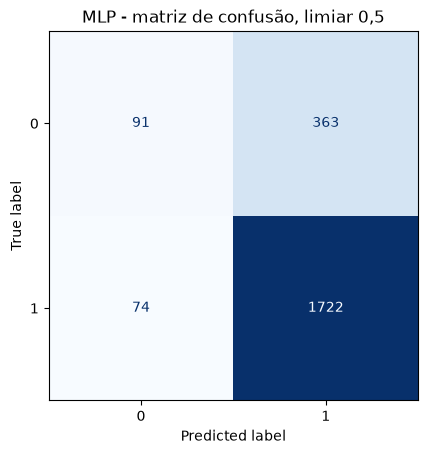

,limiar,precisão,recall,F1,alertas
0,0.25,0.800,1.000,0.889,2246
1,0.35,0.806,0.993,0.890,2213
2,0.50,0.826,0.959,0.887,2085
3,0.65,0.860,0.888,0.873,1854
4,0.75,0.887,0.792,0.837,1605


In [6]:
from sklearn.metrics import (classification_report, ConfusionMatrixDisplay,
    roc_auc_score, precision_score, recall_score, f1_score)

prob = mlp_c.predict_proba(Xc_te)[:, 1]
pred = (prob >= 0.5).astype(int)
print(classification_report(yc_te, pred, digits=3, zero_division=0))
print("ROC-AUC:", round(roc_auc_score(yc_te, prob), 3))
ConfusionMatrixDisplay.from_predictions(yc_te, pred, cmap="Blues", colorbar=False)
plt.title("MLP - matriz de confusão, limiar 0,5")
plt.show()
linhas = []
for t in [0.25, 0.35, 0.50, 0.65, 0.75]:
    p = (prob >= t).astype(int)
    linhas.append({"limiar": t, "precisão": precision_score(yc_te,p,zero_division=0),
        "recall": recall_score(yc_te,p,zero_division=0),
        "F1": f1_score(yc_te,p,zero_division=0), "alertas": int(p.sum())})
display(pd.DataFrame(linhas).round(3))

## Avaliação da regressão e diagnóstico

MAE expressa o erro médio na unidade original e costuma ser simples de interpretar. RMSE também está na unidade original, mas penaliza mais os erros grandes. R² compara o modelo com uma referência que sempre prevê a média; valor negativo significa que essa referência foi melhor no teste. Resíduos são valor real menos previsto. Padrões no gráfico podem indicar relações não aprendidas.

A curva de perda mostra o ajuste no treino; o score de validação mostra o comportamento em exemplos separados para parada antecipada. Se treino melhora e validação piora, há sinal de sobreajuste. Interprete as curvas junto com as métricas.

MAE: 14.874
RMSE: 216.156
R²: -0.0


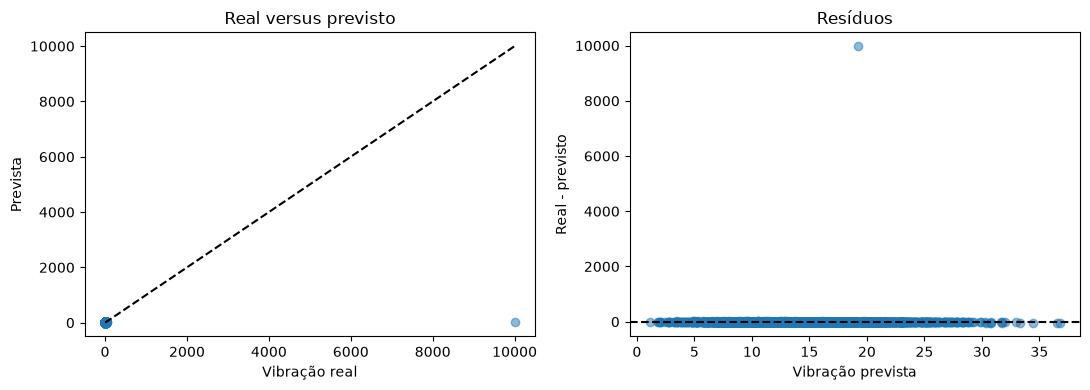

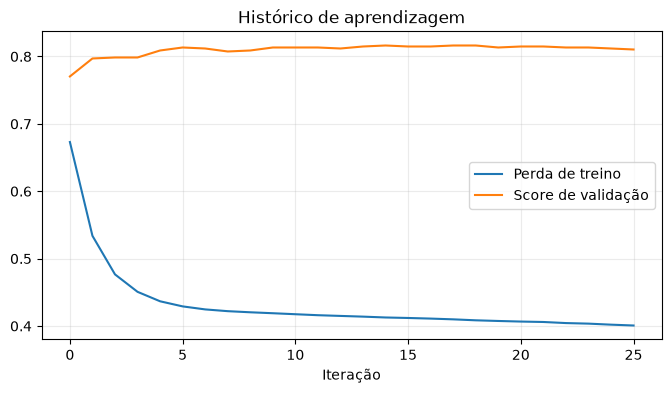

In [7]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

prev = mlp_r.predict(Xr_te)
residuos = yr_te - prev
print("MAE:", round(mean_absolute_error(yr_te, prev), 3))
print("RMSE:", round(mean_squared_error(yr_te, prev) ** 0.5, 3))
print("R²:", round(r2_score(yr_te, prev), 3))
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].scatter(yr_te, prev, alpha=0.5)
lim = [min(yr_te.min(), prev.min()), max(yr_te.max(), prev.max())]
ax[0].plot(lim, lim, "--", color="black")
ax[0].set(title="Real versus previsto", xlabel="Vibração real", ylabel="Prevista")
ax[1].scatter(prev, residuos, alpha=0.5)
ax[1].axhline(0, color="black", linestyle="--")
ax[1].set(title="Resíduos", xlabel="Vibração prevista", ylabel="Real - previsto")
plt.tight_layout(); plt.show()
rede = mlp_c.named_steps["mlp"]
plt.figure(figsize=(8, 4)); plt.plot(rede.loss_curve_, label="Perda de treino")
if getattr(rede, "validation_scores_", None) is not None:
    plt.plot(rede.validation_scores_, label="Score de validação")
plt.xlabel("Iteração"); plt.title("Histórico de aprendizagem"); plt.legend(); plt.grid(alpha=0.25); plt.show()

## Baseline: comparação com Random Forest

O baseline responde se a MLP agrega valor. Treinamos Random Forest nas mesmas partíções. Comparamos ROC-AUC para classificação e MAE para regressão. ROC-AUC maior e MAE menor são preferíveis, mas também importam latência, manutenção, estabilidade e explicabilidade.

In [8]:
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
rf_c = RandomForestClassifier(n_estimators=250, class_weight="balanced", random_state=42).fit(Xc_tr, yc_tr)
rf_r = RandomForestRegressor(n_estimators=250, random_state=42).fit(Xr_tr, yr_tr)
resultado = pd.DataFrame([
 {"tarefa":"Classificação", "modelo":"MLP", "métrica":"ROC-AUC", "valor":roc_auc_score(yc_te,prob)},
 {"tarefa":"Classificação", "modelo":"Random Forest", "métrica":"ROC-AUC", "valor":roc_auc_score(yc_te,rf_c.predict_proba(Xc_te)[:,1])},
 {"tarefa":"Regressão", "modelo":"MLP", "métrica":"MAE", "valor":mean_absolute_error(yr_te,prev)},
 {"tarefa":"Regressão", "modelo":"Random Forest", "métrica":"MAE", "valor":mean_absolute_error(yr_te,rf_r.predict(Xr_te))},
])
display(resultado.round(3))

,tarefa,modelo,métrica,valor
0,Classificação,MLP,ROC-AUC,0.774
1,Classificação,Random Forest,ROC-AUC,0.781
2,Regressão,MLP,MAE,14.874
3,Regressão,Random Forest,MAE,25.011


# CRISP-DM 6 - Implantação e monitoramento

A probabilidade de falha pode ordenar inspeções; a vibração prevista pode apoiar o planejamento. Empacote preparo e modelo juntos, registre versões de dados e software e documente entradas, saídas, limites e limiar operacional. Monitore falhas não detectadas, alarmes falsos, erro de vibração, dados ausentes e alterações nos sensores e no processo. Mudanças podem exigir investigação e nova avaliação.

Dados sintéticos não representam as condições reais da fábrica. Uso real exige dados representativos, validação temporal, análise de segurança, teste controlado e aprovação dos responsáveis.

## Exercício final - Continuidade do projeto

Compare MLPs com arquiteturas `(8,)`, `(24, 12)` e `(48, 24, 12)` nas duas tarefas. Mantenha partções e sementes fixas. Registre ROC-AUC, recall, precisão e volume de alertas na classificação; MAE, RMSE e R² na regressão. Compare cada MLP com Random Forest nas mesmas partções.

Escolha um limiar compatível com uma capacidade de inspeção definida por você e explique o efeito em falsos positivos e negativos. Entregue uma tabela e uma recomendação pelas fases do CRISP-DM: objetivo, dados, preparo, modelo, avaliação e monitoramento. Não escolha a arquitetura com base no teste; use validação dentro do treino e reserve o teste para a comparação final.

## Referências

- Scikit-learn: MLP para classificação e regressão: https://scikit-learn.org/stable/modules/neural_networks_supervised.html
- Scikit-learn: pipelines e composição de estimadores: https://scikit-learn.org/stable/modules/compose.html
- Dataset local: `Materiais/CRISP_DM_Random_Forest_Manutencao_Preditiva.csv`.